# 12.1 Research evidence synthesis

An executed presentation companion for the completed study. No new model fitting.

```mermaid
flowchart LR
    A[Collected 6.x to 11.x evidence] --> B[Check source and population]
    B --> C[ROI classification comparisons]
    B --> D[Full-image detector comparisons]
    C --> E[Explain failures and scope]
    D --> E
    E --> F[Local phone capture feasibility]
```


## 1. Scope and provenance
    Consolidate completed experiments only. Classification is measured on 1,920 validation ROIs;
    detection is measured on 327 full images. Their F1 and AP are different endpoints.
    The earlier proposed notebook 12 finalist repeats is deferred; this notebook performs no repeats.

In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, Code
ROOT = Path.cwd().resolve()
if not (ROOT/'pyproject.toml').exists(): ROOT = ROOT.parent
assert (ROOT/'src/dentalselfie').is_dir(), 'Run from the project root or notebooks directory'
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
print('Root:', ROOT, '| Python:', platform.python_version(), '| No training or test evaluation')

OUT = ROOT/'docs/reports/synthesis'; OUT.mkdir(parents=True,exist_ok=True)
TRAINING = ROOT/'docs/reports/training'
provenance = []
def load(relative):
    path = ROOT/relative
    value = json.loads(path.read_text(encoding='utf-8'))
    provenance.append({'file':relative, 'sha256':sha(path)})
    return value
manifest = ROOT/'data/processed/gum_raw_roi_v1/manifest.csv'
raw = pd.read_csv(manifest)
assert raw.query("split == 'val'").shape[0] == 1920
assert sha(manifest) == 'b9feaaceb4b9ea94ad540b553927ffb7f67e731098f7a78c770941804cbb4f06'
display(raw.groupby(['split','class_name']).size().rename('ROIs').to_frame())

Root: C:\Users\huynh\Desktop\oral-disease | Python: 3.11.15 | No training or test evaluation


ROIs
split class_name                   
train marked_inflammation      4930
      mild_inflammation        3829
      no_visible_inflammation   210
val   marked_inflammation       939
      mild_inflammation         932
      no_visible_inflammation    49

## 2. Consolidate scratch, pretrained and combined-method evidence
    Read the previously collected 6.x and 07.x summaries. No new metrics or clinical labels are generated.
    Context, learned gating and CORAL are separate hypotheses; the study did not show monotonic improvement.

In [2]:
method = load('docs/reports/training/roi_method_comparison.json')
assert method['validation_rows'] == 1920
rows=[]
for item in method['summary']:
    name=item['experiment']; detail=method['details'][name]
    rows.append({'stage':'6.x' if name.startswith('C') else '07.x', 'experiment':name,
                 'accuracy':item['accuracy'],'macro_f1':item['macro_f1'],
                 'no_visible_recall':detail['class_recall'][0], 'crop_version':'old_224',
                 'source':'roi_method_comparison.json'})
display(pd.DataFrame(rows))

,stage,experiment,accuracy,macro_f1,no_visible_recall,crop_version,source
0,6.x,C0 scratch CNN,0.716146,0.483202,0.000000,old_224,roi_method_comparison.json
1,6.x,C1 scratch ResNet18,0.697917,0.554186,0.204082,old_224,roi_method_comparison.json
2,6.x,C2 ImageNet ResNet18,0.695833,0.557576,0.224490,old_224,roi_method_comparison.json
3,07.x,M1_concat_CE,0.695312,0.535993,0.183673,old_224,roi_method_comparison.json
4,07.x,M2_gate_CE,0.670312,0.539916,0.428571,old_224,roi_method_comparison.json
5,07.x,M3_local_CORAL,0.632812,0.514593,0.653061,old_224,roi_method_comparison.json
6,07.x,M4_gate_CORAL,0.636458,0.494809,0.408163,old_224,roi_method_comparison.json


## 3. Add source-resolution, class-imbalance and frozen-feature studies
    R0/R1 isolate crop preparation, R1/R2/R3 compare objectives. P0/P1 are frozen probes.
    These interventions do not share a single matched control, so a leaderboard alone cannot explain causality.

In [3]:
recovery=load('docs/reports/training/roi_recovery_comparison.json')
for item in recovery:
    rows.append({'stage':'09.1/09.2','experiment':item['trial']['id'],
                 'accuracy':item['accuracy'],'macro_f1':item['macro_f1'],
                 'no_visible_recall':item['class_recall'][0],
                 'crop_version':item['trial']['data'],'source':'roi_recovery_comparison.json'})
probe=load('docs/reports/training/roi_foundation_probe_comparison.json')
assert probe['version']==3 and probe['status']=='COMPLETE'
for item in probe['probes']:
    rows.append({'stage':'09.3','experiment':item['trial']['id'],
                 'accuracy':item['accuracy'],'macro_f1':item['macro_f1'],
                 'no_visible_recall':item['class_recall'][0],
                 'crop_version':'raw','source':'roi_foundation_probe_comparison.json'})
display(pd.DataFrame(rows).tail(6))

,stage,experiment,accuracy,macro_f1,no_visible_recall,crop_version,source
7,09.1/09.2,R0_old_CE,0.680729,0.566060,0.428571,old,roi_recovery_comparison.json
8,09.1/09.2,R1_raw_CE,0.686979,0.572618,0.367347,raw,roi_recovery_comparison.json
9,09.1/09.2,R2_raw_CBCE,0.691146,0.573961,0.408163,raw,roi_recovery_comparison.json
10,09.1/09.2,R3_raw_BalancedSoftmax,0.670312,0.533625,0.326531,raw,roi_recovery_comparison.json
11,09.3,P0_raw_frozen_ResNet18,0.666667,0.500830,0.142857,raw,roi_foundation_probe_comparison.json
12,09.3,P1_raw_frozen_DINOv3,0.679688,0.478327,0.040816,raw,roi_foundation_probe_comparison.json


## 4. Add verified full DINOv3 results
    11.1 changes frozen readout, while 11.2 changes trainable layers under CE.
    CLS logistic regression is repeated from 09.3: list it for its matched comparison, not as independent confirmation.

In [4]:
for track in ['11_1','11_2']:
    receipt=load(f'docs/reports/training/dinov3_publication/{track}_full_v8/verification.json')
    assert receipt['state']=='COMPLETE' and receipt['test_images_opened']==0
    assert receipt['manifest_sha256']==sha(manifest)
    for item in receipt['verified_results']:
        name=item.get('feature',item.get('trial'))
        rows.append({'stage':track.replace('_','.'),'experiment':name,
                     'accuracy':item['accuracy'],'macro_f1':item['macro_f1'],
                     'no_visible_recall':item['class_recall'][0],
                     'crop_version':'raw','source':f'{track}_full_v8/verification.json'})
summary=pd.DataFrame(rows)
assert summary.experiment.notna().all() and len(summary)==17
summary.to_csv(OUT/'roi_experiment_matrix.csv',index=False)
display(summary.style.format({'accuracy':'{:.2%}','macro_f1':'{:.2%}','no_visible_recall':'{:.2%}'}))

,stage,experiment,accuracy,macro_f1,no_visible_recall,crop_version,source
0,6.x,C0 scratch CNN,71.61%,48.32%,0.00%,old_224,roi_method_comparison.json
1,6.x,C1 scratch ResNet18,69.79%,55.42%,20.41%,old_224,roi_method_comparison.json
2,6.x,C2 ImageNet ResNet18,69.58%,55.76%,22.45%,old_224,roi_method_comparison.json
3,07.x,M1_concat_CE,69.53%,53.60%,18.37%,old_224,roi_method_comparison.json
4,07.x,M2_gate_CE,67.03%,53.99%,42.86%,old_224,roi_method_comparison.json
5,07.x,M3_local_CORAL,63.28%,51.46%,65.31%,old_224,roi_method_comparison.json
6,07.x,M4_gate_CORAL,63.65%,49.48%,40.82%,old_224,roi_method_comparison.json
7,09.1/09.2,R0_old_CE,68.07%,56.61%,42.86%,old,roi_recovery_comparison.json
8,09.1/09.2,R1_raw_CE,68.70%,57.26%,36.73%,raw,roi_recovery_comparison.json
9,09.1/09.2,R2_raw_CBCE,69.11%,57.40%,40.82%,raw,roi_recovery_comparison.json


## 5. Compare performance and minority-class failure
    Plot accuracy beside macro-F1 and no-visible recall. Accuracy can rise while the rare class remains unrecognized.
    All values are extensively reused validation scores, mostly one seed. The 75% line is a project aspiration.

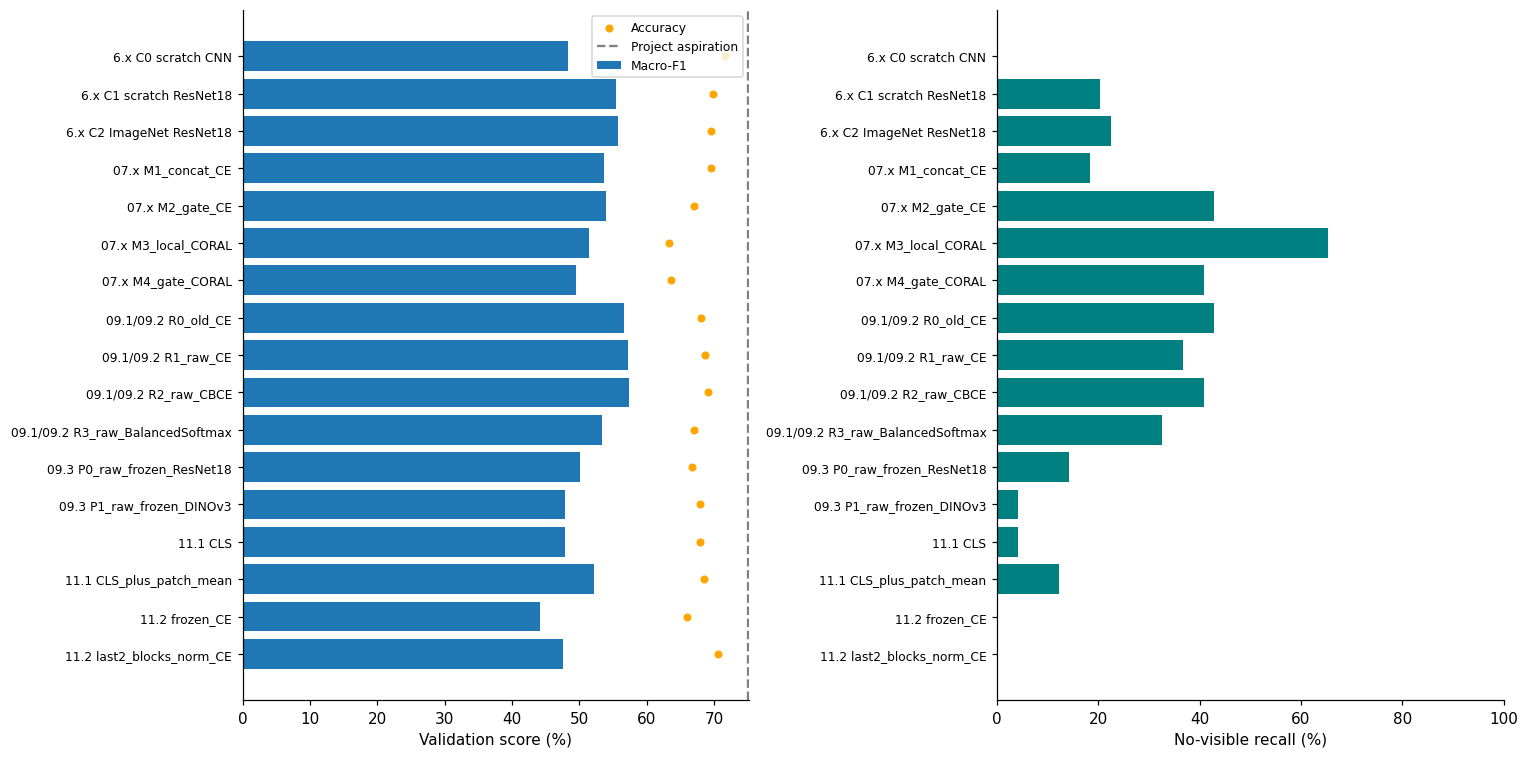

In [5]:
fig,axes=plt.subplots(1,2,figsize=(14,7))
labels=summary.stage+' '+summary.experiment
y=np.arange(len(summary))
axes[0].barh(y,summary.macro_f1*100,label='Macro-F1')
axes[0].scatter(summary.accuracy*100,y,color='orange',label='Accuracy',s=18)
axes[0].set_yticks(y,labels,fontsize=8); axes[0].invert_yaxis()
axes[0].axvline(75,ls='--',color='gray',label='Project aspiration'); axes[0].legend(fontsize=8)
axes[0].set_xlabel('Validation score (%)')
axes[1].barh(y,summary.no_visible_recall*100,color='teal')
axes[1].set_yticks(y,labels,fontsize=8); axes[1].invert_yaxis()
axes[1].set_xlabel('No-visible recall (%)'); axes[1].set_xlim(0,100)
fig.tight_layout(); fig.savefig(OUT/'roi_research_progression.png'); plt.show()

## 6. Keep the detector evidence separate
    Reuse the executed 10.2 audit, including fixed blur, darkness and JPEG stress.
    Calculate annotation-relative precision/recall at confidence 0.25 from saved counts.
    These are not the native AP curve's precision/recall values and not phone-photo accuracy.

,model,variant,map50,map50_95,precision_at_025,recall_at_025
0,YOLOv8n,clean,0.935446,0.727273,0.787117,0.950664
1,YOLOv8n,blur_r1_5,0.934536,0.721264,0.834526,0.885199
2,YOLOv8n,dark_0_65,0.932635,0.721714,0.782132,0.946869
3,YOLOv8n,jpeg_q35,0.933672,0.722987,0.783085,0.948767
4,YOLO26n,clean,0.941227,0.730115,0.876209,0.859583
5,YOLO26n,blur_r1_5,0.937436,0.726929,0.895127,0.801708
6,YOLO26n,dark_0_65,0.940942,0.718983,0.893443,0.827324
7,YOLO26n,jpeg_q35,0.939082,0.729815,0.868726,0.853890


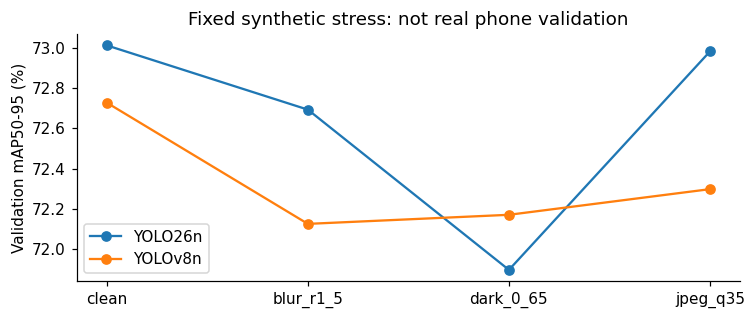

In [6]:
caries=load('docs/reports/post09/caries/summary.json')
assert caries['validation_images']==327 and caries['test_images_opened']==0
native=pd.read_csv(ROOT/'docs/reports/post09/caries/native_detection_metrics.csv')
errors=pd.read_csv(ROOT/'docs/reports/post09/caries/per_image_errors.csv')
counts=errors.groupby(['model','variant'])[['ground_truth','true_positive','missed','duplicate','localization','unmatched']].sum()
counts['apparent_fp']=counts[['duplicate','localization','unmatched']].sum(axis=1)
counts['precision_at_025']=counts.true_positive/(counts.true_positive+counts.apparent_fp)
counts['recall_at_025']=counts.true_positive/counts.ground_truth
detectors=native.merge(counts.reset_index(),on=['model','variant'],validate='one_to_one')
detectors.to_csv(OUT/'caries_detector_matrix.csv',index=False)
display(detectors[['model','variant','map50','map50_95','precision_at_025','recall_at_025']])
fig,ax=plt.subplots(figsize=(7,3))
for name,group in detectors.groupby('model'): ax.plot(group.variant,group.map50_95*100,marker='o',label=name)
ax.set(ylabel='Validation mAP50-95 (%)',title='Fixed synthetic stress: not real phone validation')
ax.legend(); fig.tight_layout();fig.savefig(OUT/'caries_stress_summary.png');plt.show()

## 7. Presentation narrative and evidence gaps
    Explain hypotheses and measured outcomes honestly. A failed combination still contributes an interpretable ablation.
    Annotation review is pending; no class regrouping or relabelling is performed here.

In [7]:
story=pd.DataFrame([
 ['6.x','Can a learned CNN and residual learning establish a reference?','Scratch and ImageNet controls completed.'],
 ['07.x','Do wider context, gating or ordinal loss help?','Controlled variants did not surpass C2.'],
 ['08-09.x','Are source detail and imbalance limiting performance?','Small observed gains; R1/R2 remain near-tied.'],
 ['10.x','Are errors shared, and does caries detection localize lesions?','Technical audit passed; clinical and capture-domain review pending.'],
 ['11.x','Do spatial foundation features or limited adaptation help?','Matched gains, but below ResNet18; minority failures persist.'],
 ['12.x','Can ordinary phone captures support the intended workflow?','Local feasibility study prepared; real captures required.']],
 columns=['stage','research_question','measured_conclusion'])
story.to_csv(OUT/'presentation_story.csv',index=False);display(story)
review=pd.read_csv(ROOT/'docs/reports/post09/gingival/reviewer_sheet.csv')
display(Markdown(f'**Existing reviewer sheet:** {len(review)} rows in `docs/reports/post09/gingival/reviewer_sheet.csv`. '
                 'Keep original labels unchanged. Qualified review remains pending.'))
gaps=pd.DataFrame([
 ['Independent phone capture domain','Pending real images; no accuracy without reference labels'],
 ['Gingival no-visible recognition','Unresolved; do not describe no-visible as verified healthy'],
 ['11.2 inference checkpoint','Not collected: Kaggle temp checkpoints were not exported'],
 ['Repeated seeds and final test','Not completed; test stays locked'],
 ['Android inference','Deferred; desktop CPU timing is not phone latency']],columns=['gap','status'])
display(gaps);gaps.to_csv(OUT/'evidence_gaps.csv',index=False)

,stage,research_question,measured_conclusion
0,6.x,Can a learned CNN and residual learning establ...,Scratch and ImageNet controls completed.
1,07.x,"Do wider context, gating or ordinal loss help?",Controlled variants did not surpass C2.
2,08-09.x,Are source detail and imbalance limiting perfo...,Small observed gains; R1/R2 remain near-tied.
3,10.x,"Are errors shared, and does caries detection l...",Technical audit passed; clinical and capture-d...
4,11.x,Do spatial foundation features or limited adap...,"Matched gains, but below ResNet18; minority fa..."
5,12.x,Can ordinary phone captures support the intend...,Local feasibility study prepared; real capture...


**Existing reviewer sheet:** 114 rows in `docs/reports/post09/gingival/reviewer_sheet.csv`. Keep original labels unchanged. Qualified review remains pending.

,gap,status
0,Independent phone capture domain,Pending real images; no accuracy without refer...
1,Gingival no-visible recognition,Unresolved; do not describe no-visible as veri...
2,11.2 inference checkpoint,Not collected: Kaggle temp checkpoints were no...
3,Repeated seeds and final test,Not completed; test stays locked
4,Android inference,Deferred; desktop CPU timing is not phone latency


## 8. Save the evidence receipt and next action
    No additional training, uploads or test evaluation occur. The paired photo notebook is local-only.
    Freeze the present comparison and collect feasible ordinary captures before choosing another model experiment.

In [8]:
receipt={'roi_rows':len(summary),'roi_validation_population':1920,'detector_rows':len(detectors),
         'detector_validation_images':327,'test_images_opened':0,'training_started':False,
         'sources':provenance,'next_action':'Collect local phone captures and run notebook 12.2',
         'personal_photos_uploaded':False}
(OUT/'receipt.json').write_text(json.dumps(receipt,indent=2),encoding='utf-8')
display(pd.Series({k:v for k,v in receipt.items() if k!='sources'}).to_frame('evidence'))
print('Saved evidence matrix, figures and source hashes:', OUT)

,evidence
roi_rows,17
roi_validation_population,1920
detector_rows,8
detector_validation_images,327
test_images_opened,0
training_started,False
next_action,Collect local phone captures and run notebook ...
personal_photos_uploaded,False


Saved evidence matrix, figures and source hashes: C:\Users\huynh\Desktop\oral-disease\docs\reports\synthesis
